# Inferring liquidity from observed price ranges

The relative effective spread measures twice the signed distance between a transaction price and an unobserved fair price:

$$
S_t=\frac{2D_t(P_t-\widetilde P_t)}{\widetilde P_t},
\qquad D_t\in\{-1,1\}.
$$

Here, $S_t$ is the proportional effective spread for trade $t$; $P_t$ is the observed transaction price. $\widetilde P_t$ is the unobserved fair price; $D_t=1$ for a buyer-initiated trade and $D_t=-1$ for a seller-initiated trade.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.features.microstructural_features import alpha_estimates, bekker_parkinson_volatility_estimates, beta_estimates, corwin_schultz_estimator, edge_estimator, gamma_estimates, sigma_estimates
numeric_columns = ['Open', 'High', 'Low', 'close', 'volume', 'quote_volume', 'trades']
raw[numeric_columns] = raw[numeric_columns].apply(pd.to_numeric)
minute = raw.rename(columns={'Open': 'open', 'High': 'high', 'Low': 'low'}).set_index('time')[['open', 'high', 'low', 'close', 'volume', 'quote_volume', 'trades']]

def make_bars(rule):
    return minute.resample(rule).agg({'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum', 'quote_volume': 'sum', 'trades': 'sum'}).dropna()
bars_15 = make_bars('15min')
FIGURES = ROOT / 'outputs' / 'figures' / '11_market_microstructure'
TABLES = ROOT / 'outputs' / 'tables' / '11_market_microstructure'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Building range-based liquidity measures

,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Market,BTCUSDT spot
3,Interval,One minute
4,Start,2021-01-01 00:00:00
5,End,2021-01-31 23:59:00
6,One-minute rows,"44,640"
7,Fifteen-minute bars,"2,976"


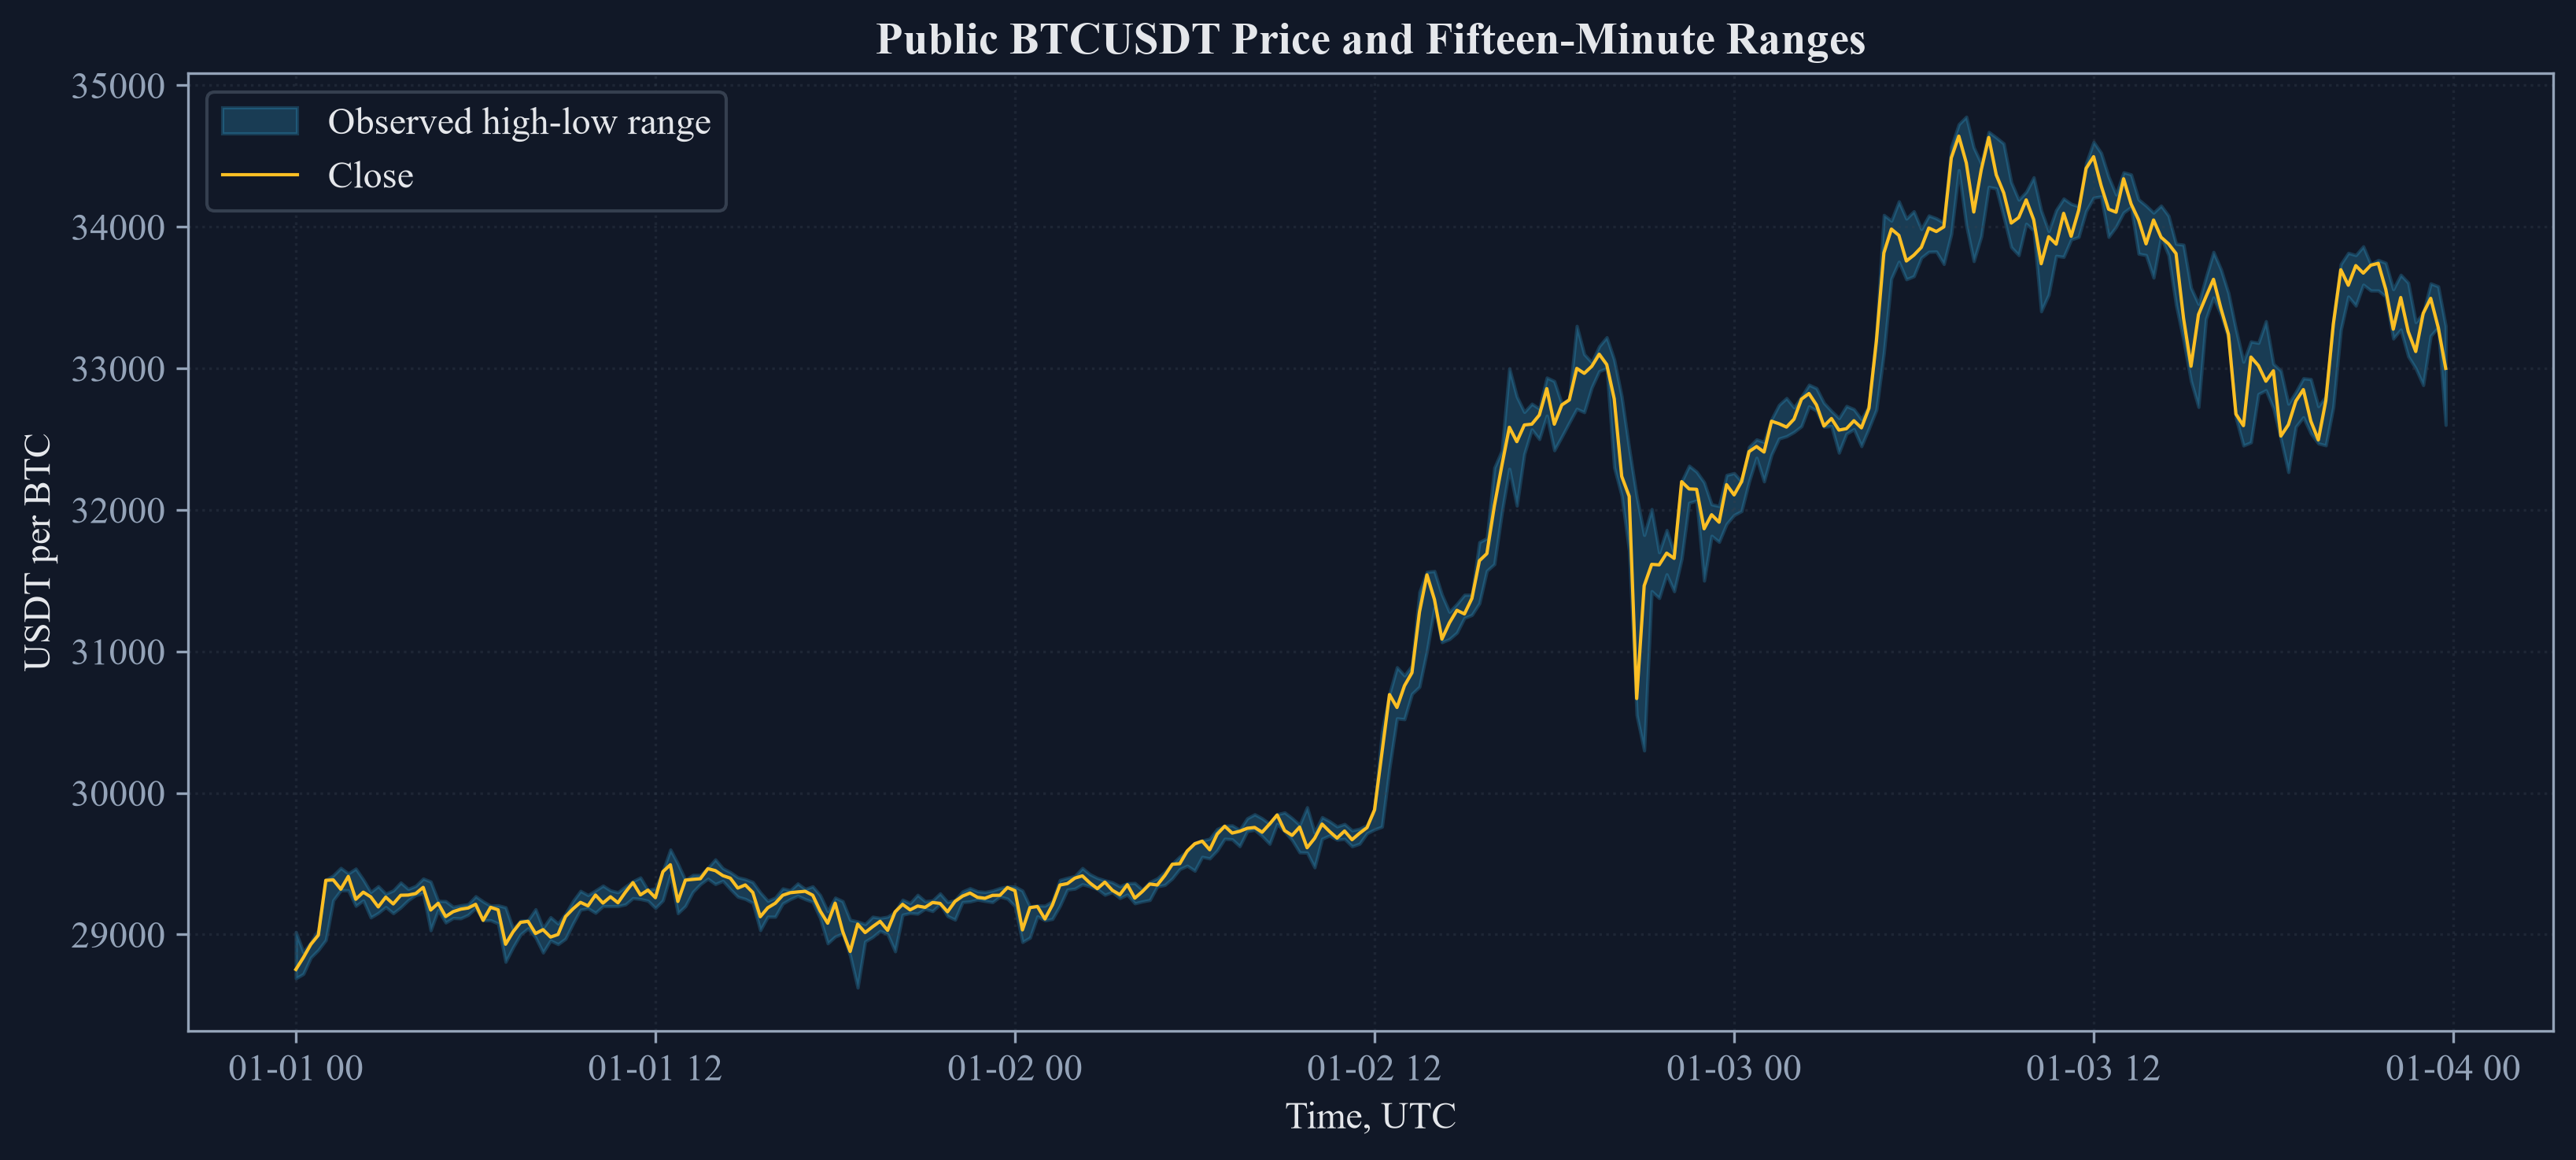

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Market', 'Interval', 'Start', 'End', 'One-minute rows', 'Fifteen-minute bars'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'BTCUSDT spot', 'One minute', str(minute.index.min()), str(minute.index.max()), f'{len(minute):,}', f'{len(bars_15):,}']})
save_table(data_provenance, 'data_provenance', 'Public observations used in Chapter 10.', 'tab:chapter10-data-provenance', fit=True)
display(data_provenance)
public_window = bars_15.iloc[:96 * 3]
figure, axis = plt.subplots(figsize=(10.8, 4.8), constrained_layout=True)
axis.fill_between(public_window.index, public_window['low'], public_window['high'], color=palette['cyan'], alpha=0.22, label='Observed high-low range')
axis.plot(public_window.index, public_window['close'], color=palette['amber'], linewidth=1.0, label='Close')
axis.set_title('Public BTCUSDT Price and Fifteen-Minute Ranges')
axis.set_xlabel('Time, UTC')
axis.set_ylabel('USDT per BTC')
axis.legend()
axis.grid(alpha=0.35)
figure.savefig(FIGURES / 'public_price_ranges.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'public_price_ranges.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'public_price_ranges.png')))
plt.close(figure)


## Range-Based Volatility

The logarithmic high-low range records the movement inside a bar, and the Parkinson calculation converts squared ranges into a variance estimate:

$$
R_t^{HL}=\log\!\left(\frac{H_t}{L_t}\right),
\qquad
\widehat\sigma_{P,m}^{2}
=\frac{1}{4m\log 2}\sum_{t=1}^{m}\left(R_t^{HL}\right)^2.
$$

Here, $H_t$ and $L_t$ are the observed high and low in bar $t$; $R_t^{HL}$ is that bar's logarithmic range. $m$ is the number of bars in the estimate; $\widehat\sigma_{P,m}^{2}$ is range-based variance per bar; $\log$ is the natural logarithm.

The close-to-close calculation estimates variance from one observed close change per bar and provides a comparison for the range calculation:

$$
\widehat\sigma_{C,m}^{2}
=\frac{1}{m}\sum_{t=1}^{m}
\left(\log C_t-\log C_{t-1}\right)^2.
$$

Here, $C_t$ is the close in bar $t$; $m$ is the number of squared close changes. $\widehat\sigma_{C,m}^{2}$ is close-to-close variance per bar; $\log C_t-\log C_{t-1}$ is the logarithmic close return.

In [3]:
frequency_specification = [("One minute", "1min", 1440), ("Five minutes", "5min", 288), ("Fifteen minutes", "15min", 96), ("One hour", "1h", 24), ("One day", "1D", 1)]
frequency_rows = []
for name, rule, bars_per_day in frequency_specification:
    current = make_bars(rule)
    log_range = np.log(current["high"] / current["low"])
    close_return = np.log(current["close"]).diff()
    range_daily = np.sqrt(np.mean(log_range**2) * bars_per_day / (4 * np.log(2)))
    close_daily = np.sqrt(np.mean(close_return.dropna() ** 2) * bars_per_day)
    frequency_rows.append({"Bar length": name, "Bars": len(current), "Median range, basis points": 10000 * log_range.median(), "Mean trades per bar": current["trades"].mean(), "Range volatility, daily": range_daily, "Close volatility, daily": close_daily, "Range to close ratio": range_daily / close_daily})
range_volatility_summary = pd.DataFrame(frequency_rows)
save_table(range_volatility_summary, "range_volatility_summary", "Observed ranges and two daily volatility calculations across bar lengths.", "tab:chapter10-range-volatility-summary", fit=True)
display(range_volatility_summary.round(6))

log_range_15 = np.log(bars_15["high"] / bars_15["low"])
range_quantiles = pd.DataFrame({
    "Quantity": ["Log range, basis points", "Trades per bar", "Quote volume, million USDT"],
    "Minimum": [10000 * log_range_15.min(), bars_15["trades"].min(), bars_15["quote_volume"].min() / 1e6],
    "10th percentile": [10000 * log_range_15.quantile(0.10), bars_15["trades"].quantile(0.10), bars_15["quote_volume"].quantile(0.10) / 1e6],
    "Median": [10000 * log_range_15.median(), bars_15["trades"].median(), bars_15["quote_volume"].median() / 1e6],
    "90th percentile": [10000 * log_range_15.quantile(0.90), bars_15["trades"].quantile(0.90), bars_15["quote_volume"].quantile(0.90) / 1e6],
    "Maximum": [10000 * log_range_15.max(), bars_15["trades"].max(), bars_15["quote_volume"].max() / 1e6],
})
save_table(range_quantiles, "range_quantiles", "Distribution of public fifteen-minute range and activity measurements.", "tab:chapter10-range-quantiles", fit=True)
display(range_quantiles.round(6))

,Bar length,Bars,"Median range, basis points",Mean trades per bar,"Range volatility, daily","Close volatility, daily",Range to close ratio
0,One minute,44640,21.261782,1.651380e+03,0.075795,0.076950,0.984988
1,Five minutes,8928,50.769698,8.256899e+03,0.077706,0.075687,1.026675
2,Fifteen minutes,2976,92.480963,2.477070e+04,0.078114,0.076391,1.022552
3,One hour,744,193.255060,9.908279e+04,0.077523,0.069588,1.114026
4,One day,31,1040.766168,2377987,0.071913,0.055264,1.301262


,Quantity,Minimum,10th percentile,Median,90th percentile,Maximum
0,"Log range, basis points",18.327179,48.712138,92.480963,187.590439,1003.557625
1,Trades per bar,5727,12915.500000,21203,39295,196911
2,"Quote volume, million USDT",4.742545,15.773619,31.510414,72.202752,437.063159


## Rolling Comparison

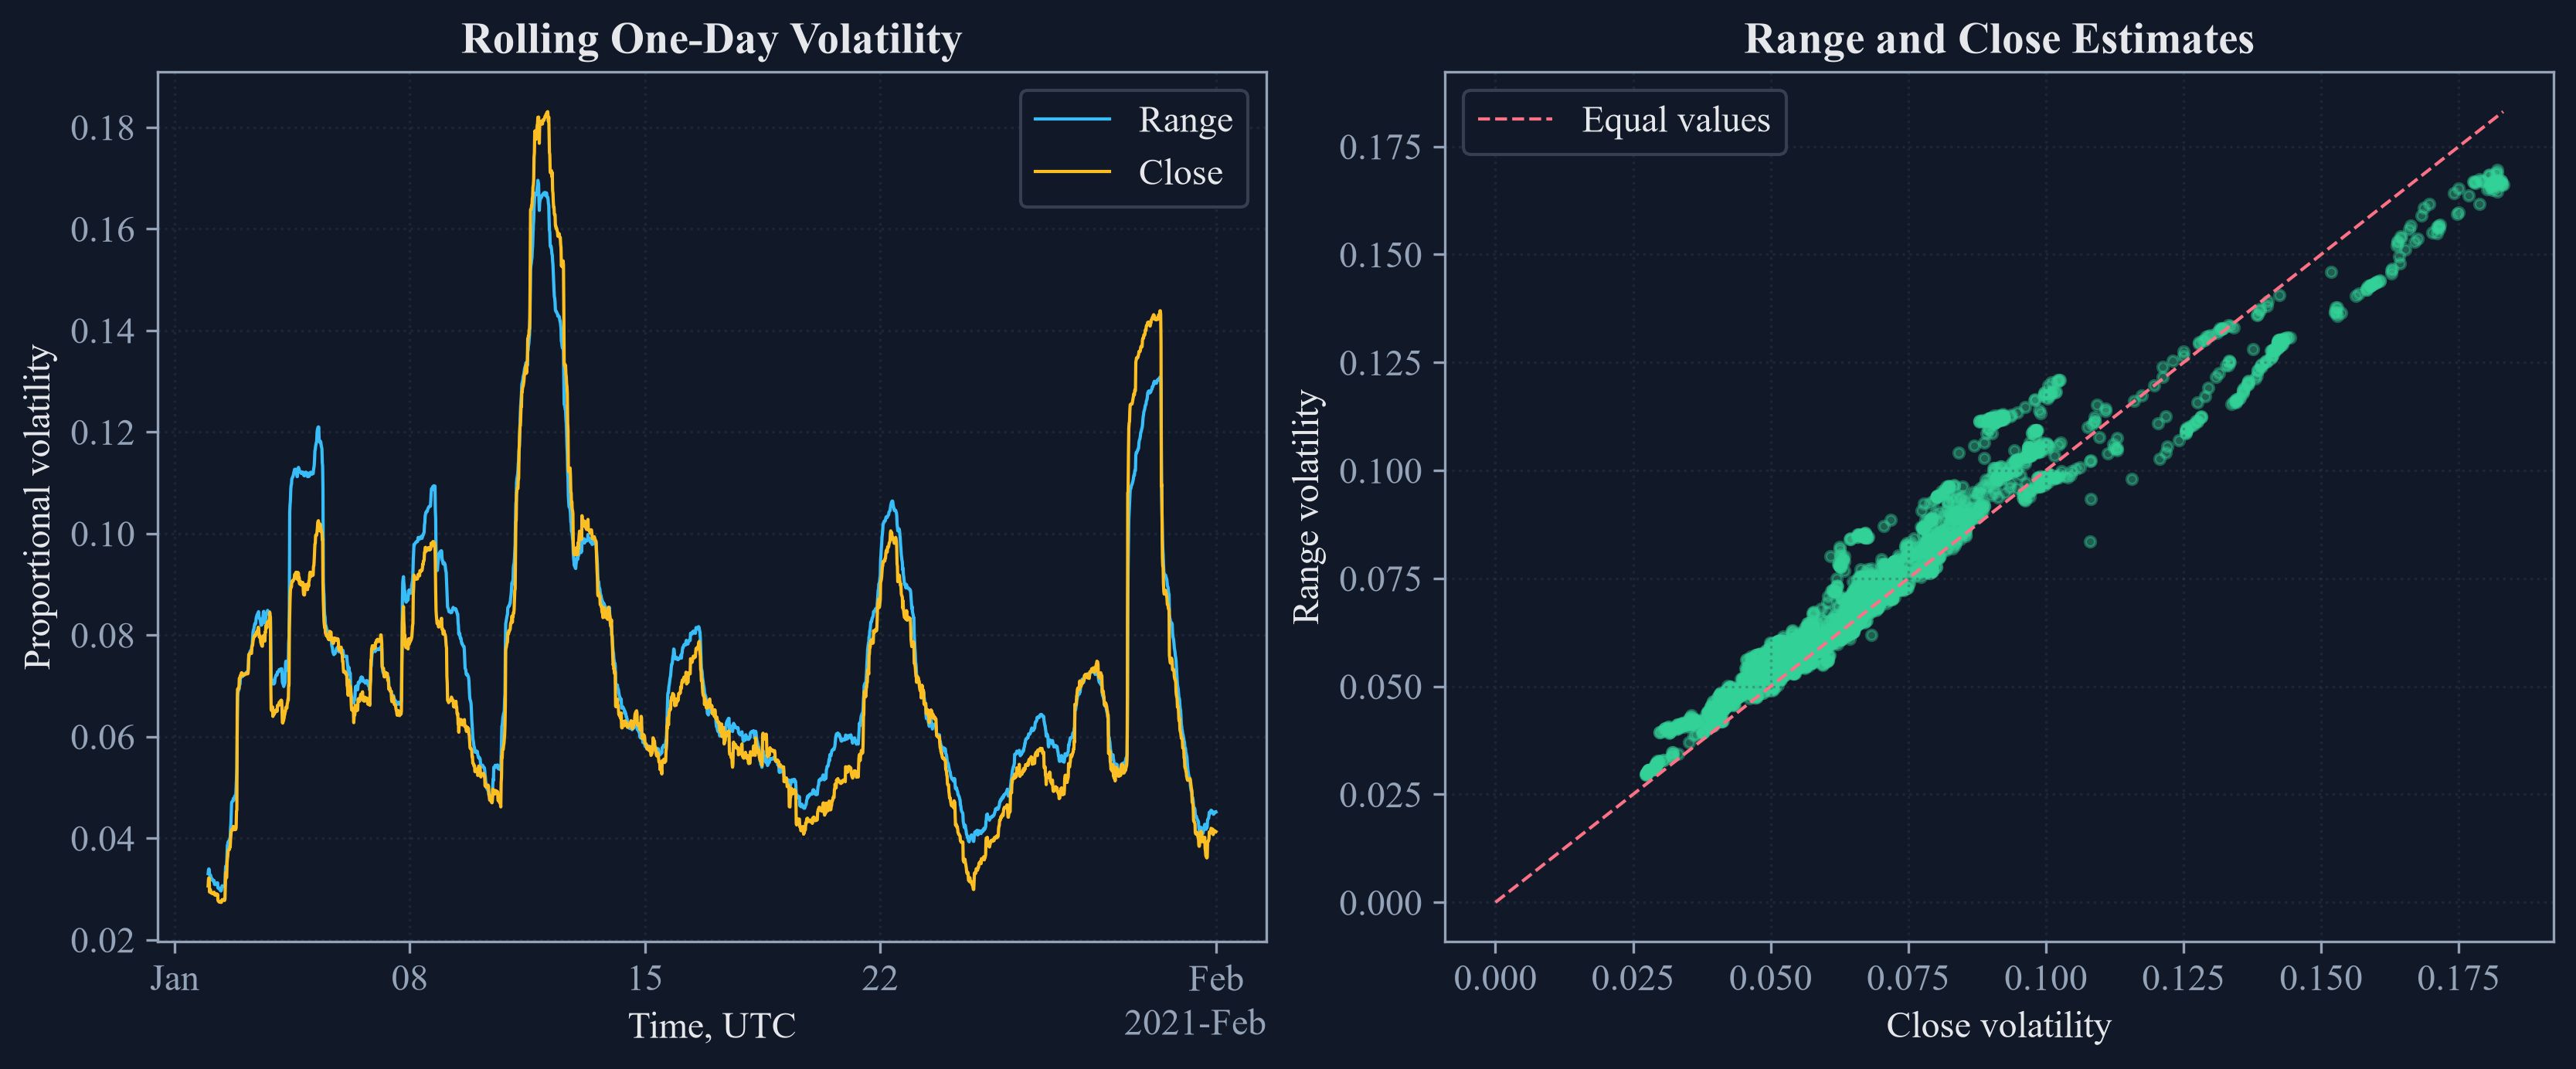

In [4]:
rolling_bars = 96
rolling_range_volatility = np.sqrt(log_range_15.pow(2).rolling(rolling_bars).mean() * rolling_bars / (4 * np.log(2)))
rolling_close_volatility = np.sqrt(np.log(bars_15["close"]).diff().pow(2).rolling(rolling_bars).mean() * rolling_bars)
rolling_comparison = pd.concat([rolling_range_volatility.rename("Range"), rolling_close_volatility.rename("Close")], axis=1).dropna()

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.5), constrained_layout=True)
axes[0].plot(rolling_comparison.index, rolling_comparison["Range"], color=palette["cyan"], linewidth=1.0, label="Range")
axes[0].plot(rolling_comparison.index, rolling_comparison["Close"], color=palette["amber"], linewidth=1.0, label="Close")
axes[0].set_title("Rolling One-Day Volatility")
axes[0].set_xlabel("Time, UTC")
axes[0].set_ylabel("Proportional volatility")
axes[0].legend()
axes[0].grid(alpha=0.35)
locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
axes[0].xaxis.set_major_locator(locator)
axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[1].scatter(rolling_comparison["Close"], rolling_comparison["Range"], s=10, alpha=0.38, color=palette["green"])
diagonal_max = rolling_comparison.to_numpy().max()
axes[1].plot([0, diagonal_max], [0, diagonal_max], color=palette["rose"], linewidth=1.0, linestyle="--", label="Equal values")
axes[1].set_title("Range and Close Estimates")
axes[1].set_xlabel("Close volatility")
axes[1].set_ylabel("Range volatility")
axes[1].legend()
axes[1].grid(alpha=0.35)
figure.savefig(FIGURES / "range_volatility_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "range_volatility_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "range_volatility_comparison.png")))
plt.close(figure)

## Tests

In [5]:
assert len(minute) == 44640
assert len(bars_15) == 2976
assert minute.index.min() == pd.Timestamp('2021-01-01 00:00:00')
assert minute.index.max() == pd.Timestamp('2021-01-31 23:59:00')
assert bars_15.index.is_monotonic_increasing
assert not bars_15.isna().any().any()
assert (bars_15['high'] >= bars_15[['open', 'close']].max(axis=1)).all()
assert (bars_15['low'] <= bars_15[['open', 'close']].min(axis=1)).all()
assert (bars_15['high'] >= bars_15['low']).all()
assert (log_range_15 >= 0).all()
assert range_volatility_summary['Bars'].tolist() == [44640, 8928, 2976, 744, 31]
assert range_volatility_summary['Mean trades per bar'].is_monotonic_increasing
assert range_volatility_summary[['Range volatility, daily', 'Close volatility, daily']].gt(0).all().all()
assert len(rolling_comparison) == len(bars_15) - rolling_bars
assert rolling_comparison.gt(0).all().all()
assert np.isfinite(rolling_comparison.to_numpy()).all()
assert (FIGURES / 'public_price_ranges.pdf').is_file()
assert (FIGURES / 'range_volatility_comparison.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'range_volatility_summary.tex').is_file()
assert (TABLES / 'range_quantiles.tex').is_file()
